# Wadi Ghadir ground magnetic survey – processing chain

**Wadi Ghadir, Eastern Desert, Egypt · total-field ground magnetics · January 2026**

**Prepared by Dr. Mohamed Sobh, LIAG** (Leibniz Institute for Applied Geophysics)

This notebook processes the diurnally corrected total-field data supplied by the field team: QC and
despiking, removal of the IGRF-14 main field, gridding, reduction to the pole (RTP) and maps in the same
style and palette as the gravity maps. Every step calls one method of `wghadir.chains.MagneticChain`;
the tunable values are in `wghadir/magnetic/settings.py`.

| Step | Processing | Output |
|---:|---|---|
| 1 | Load all rows, UTM 36N coordinates, survey days from the time stamps | table 30 |
| 2 | Despike: Hampel filter within each day | table 30 |
| 3 | IGRF-14 total field → total-field anomaly TMA = TMI − IGRF | table 30 |
| 4 | QC statistics: day summary, crossovers, IGRF date sensitivity | tables 31–33 |
| 5 | Gridding of TMI and TMA (block median + biharmonic spline) | `grids/mag_tmi`, `mag_tma` |
| 6 | Reduction to the pole (FFT, tapered and padded grid) | `grids/mag_rtp` |
| 7 | Maps: points and grids of TMI, TMA and RTP | `magnetics/mag01–mag05` |
| 8 | Export: tables, grids, Excel workbook, summary | `deliverables/` |

**Important assumption:** the file carries times but no dates. The IGRF is evaluated for
**20 January 2026** (middle of the gravity campaign). Step 4 shows the secular variation: about 27 nT per year
(±14 nT for ±6 months), a near-constant shift over the survey area that does not change the anomaly pattern.

Run the gravity notebook first if base 100 should be taken from the gravity solution and the DEM is not
yet in `data/external/`.

## 0  Set-up: paths and the chain object

In [1]:
# --- setup -------------------------------------------------------------------------------
# Author: Dr. Mohamed Sobh, LIAG
import os
import sys
import warnings

import numpy as np
import pandas as pd

# make the wghadir package importable when it is not pip-installed (repository layout)
REPO = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
if os.path.abspath(REPO) not in sys.path:
    sys.path.insert(0, os.path.abspath(REPO))

warnings.filterwarnings("ignore", category=FutureWarning)      # verbose third-party deprecation notes
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

from wghadir.common.display import show_figure, show_figures

from wghadir.chains import MagneticChain
from wghadir.magnetic import settings

MAG_FILE     = os.path.join(REPO, "data", "raw", "magnetics", "All_Data_Corrected_Total_Intensity.xlsx")
EXTERNAL_DIR = os.path.join(REPO, "data", "external")   # Copernicus DEM for the relief
OUT_DIR      = os.path.join(REPO, "outputs")

chain = MagneticChain(mag_file=MAG_FILE, external_dir=EXTERNAL_DIR, out_dir=OUT_DIR)
pd.DataFrame([(n, getattr(settings, n)) for n in ("SURVEY_DATE", "HAMPEL_WINDOW", "HAMPEL_K", "HAMPEL_FLOOR_NT",
                                                 "CROSSOVER_M", "BLOCK_M", "GRID_SPACING_M", "MASK_KM", "TAPER_KM")],
             columns=["setting", "value"])

,setting,value
0,SURVEY_DATE,2026-01-20 00:00:00
1,HAMPEL_WINDOW,11
2,HAMPEL_K,6.0000
3,HAMPEL_FLOOR_NT,30.0000
4,CROSSOVER_M,5.0000
5,BLOCK_M,100.0000
6,GRID_SPACING_M,50.0000
7,MASK_KM,2.0000
8,TAPER_KM,3.0000


## 1  Load the data

All rows of the workbook are kept with their Excel row number. Columns: latitude, longitude, UTM x/y and
elevation as supplied, raw reading, time (hhmmss) and the diurnally corrected total field. UTM 36N
coordinates are recomputed from latitude/longitude and compared with the supplied x/y. Survey days are
identified where the time steps back by more than 30 minutes.

In [2]:
data = chain.step01_load()
display(data[["source_row", "day_seq", "time_hhmmss", "lat", "lon", "reading_nT", "diurnal_corr_nT",
              "tmi_corr_nT"]].head())
print(f"UTM check (recomputed vs supplied): median {np.nanmedian(data['utm_check_m']):.2f} m")

[1] 12163 rows, 12161 survey readings, 10 survey days


,source_row,day_seq,time_hhmmss,lat,lon,reading_nT,diurnal_corr_nT,tmi_corr_nT
0,2,1,114913.0000,24.7789,34.8590,42096.8900,-11.0000,42085.8900
1,3,1,115007.0000,24.7789,34.8590,42097.1400,-11.0000,42086.1400
2,4,1,115022.0000,24.7789,34.8590,42097.3400,-11.0000,42086.3400
3,5,1,115155.0000,24.7790,34.8591,42098.0000,-11.0000,42087.0000
4,6,1,123025.0000,24.7801,34.8583,42098.1700,-7.0000,42091.1700


UTM check (recomputed vs supplied): median 0.01 m


## 2  Despiking

A Hampel filter runs along the readings of each day: a reading is a spike if it deviates from the running
median of 11 readings (~28 m) by more than max(30 nT, 6 × 1.4826 × MAD). Rejected readings are kept in
the table with the flag `SPIKE_HAMPEL`.

In [3]:
chain.step02_despike().rename('rows').to_frame()

[2] 155 spikes rejected; 12006 readings accepted


,rows
flags,
SPIKE_HAMPEL,155
UTM_FROM_LATLON,46
NON_DATA_ROW,2


## 3  IGRF-14 main field and total-field anomaly

The IGRF-14 field (ppigrf) is computed at every reading position and elevation: total field F, inclination I
and declination D. The total-field anomaly is TMA = TMI(corrected) − F(IGRF).

In [4]:
display(chain.step03_igrf())
print(f"field direction for the RTP: I = {chain.inc:.2f} deg, D = {chain.dec:.2f} deg")

[3] IGRF-14 2026-01-20 (assumed): I = 36.74 deg, D = 4.22 deg


,igrf_F_nT,tma_nT
count,12161.0000,12161.0000
mean,41967.4599,-86.0634
std,24.5118,364.0572
min,41932.1179,-1948.2164
25%,41942.3579,-314.9454
50%,41971.1941,-94.8755
75%,41992.2513,-50.3704
max,42023.9119,2000.2221


field direction for the RTP: I = 36.74 deg, D = 4.22 deg


## 4  QC statistics

Per-day summary (diurnal correction range, field statistics), crossovers between readings < 5 m apart on
different days, and the sensitivity of the IGRF to the assumed survey date.

In [5]:
display(chain.step04_qc_statistics())
display(chain.crossovers)
chain.igrf_sensitivity

[4] 3 crossover pairs (< 5 m, different days)


,day_seq,n_readings,n_accepted,time_first,time_last,lon_median,lat_median,diurnal_min_nT,diurnal_max_nT,tmi_median_nT,tmi_min_nT,tmi_max_nT
0,1,52,51,114913.0000,133037.0000,34.8399,24.7837,-104.0000,0.0000,42037.3850,41889.9000,42093.0300
1,2,1463,1459,93713.0000,140032.0000,34.8421,24.8013,-9.0000,-0.2000,42015.7700,41519.6400,42449.0200
2,3,1322,1317,65249.0000,140820.0000,34.7946,24.7754,-36.0000,-0.5000,41894.2650,41795.9500,42162.6800
3,4,158,148,101452.0000,140016.0000,34.7834,24.7318,-80.0000,-2.0000,41832.3150,41305.4400,42076.2200
4,5,5199,5109,71234.0000,132402.0000,34.7746,24.7216,-170.0000,-3.0000,41604.2300,39988.7400,43937.1900
5,6,1897,1889,83431.0000,142316.0000,34.8204,24.8097,-80.0000,-5.0000,41867.3100,41755.9700,42174.9600
6,7,330,325,80252.0000,145116.0000,34.8624,24.7418,-12.0000,-2.0000,41890.0050,41754.9600,42459.2200
7,8,1453,1440,72958.0000,144310.0000,34.8353,24.8130,-44.0000,-3.0000,41917.9400,41569.4600,42296.2400
8,9,241,226,75825.0000,145122.0000,34.8881,24.7204,-21.0000,-10.0000,41813.9300,41479.3500,42040.2700
9,10,46,42,72302.0000,95604.0000,34.9040,24.7766,-16.0000,-0.2000,42105.4300,41436.2000,42695.0000


,day_a,day_b,n_pairs,median_dTMI_nT,mad_dTMI_nT
0,1,10,3,-4.9100,0.2000


,date,F_nT,inc_deg,dec_deg
0,2025-01-15,41943.8231,36.7077,4.2151
1,2025-07-15,41957.4668,36.7252,4.2190
2,2026-01-20,41971.7180,36.7435,4.2230
3,2026-07-15,41984.9929,36.7606,4.2268


## 5  Gridding

As for gravity: UTM 36N, 100 m block median, linear trend + damped biharmonic spline (verde), 50 m grid,
nodes farther than 2 km from data blanked. The block K-fold cross-validation error measures how well the
grid predicts withheld data.

In [6]:
pd.Series(chain.step05_gridding(), name='cross-validation rms [nT]').to_frame()

[5] grids 50 m; cross-validation rms TMI 169.1 nT, TMA 169.1 nT


,cross-validation rms [nT]
tmi,169.0979
tma,169.0767


## 6  Reduction to the pole

The TMA is gridded on an area extended by 5 km, tapered (sin²) to the median value beyond the data mask,
padded by 50 % and reduced to the pole in the wavenumber domain (Harmonica), assuming induced magnetisation
along the IGRF field direction (I ≈ 36.7°, D ≈ 4.2°). The result is cut back to the map area and blanked
like the other grids.

In [7]:
rtp = chain.step06_reduction_to_pole()
rtp

[6] RTP range -541 to 2872 nT


<xarray.Dataset> Size: 2MB
Dimensions:   (easting: 652, northing: 418)
Coordinates:
  * easting   (easting) float64 5kB 6.723e+05 6.724e+05 ... 7.048e+05 7.049e+05
  * northing  (northing) float64 3kB 2.729e+06 2.729e+06 ... 2.75e+06 2.75e+06
Data variables:
    value     (northing, easting) float64 2MB nan nan nan nan ... nan nan nan

## 7  Maps

Five maps at 400 dpi on the DEM relief, with histogram-equalised colours (each colour band holds the same
number of values) so the strong anomaly does not compress the rest of the range.

[7] maps mag01-mag05 in ../outputs/magnetics


`mag01_TMI_points.png`

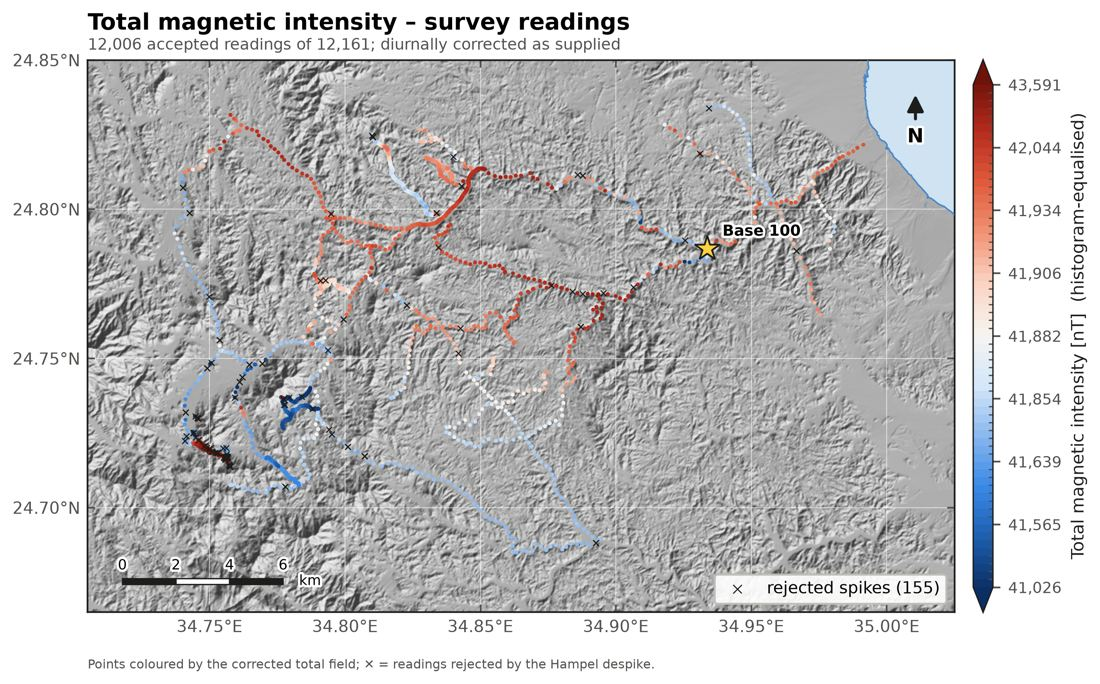

`mag02_TMA_points.png`

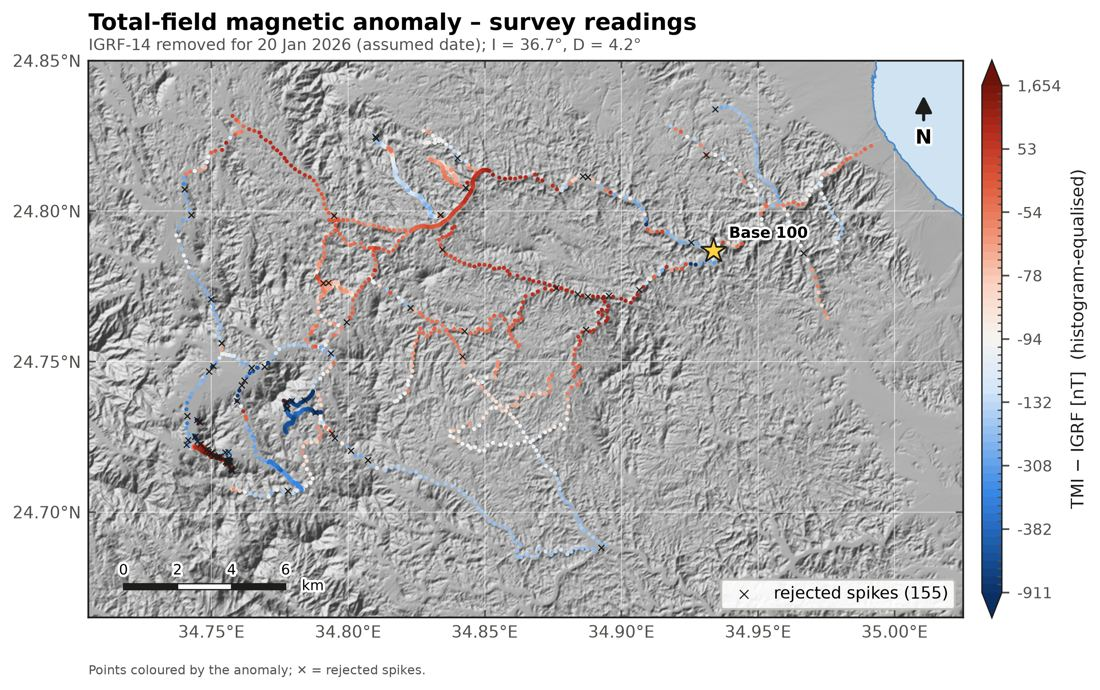

`mag03_TMI_grid.png`

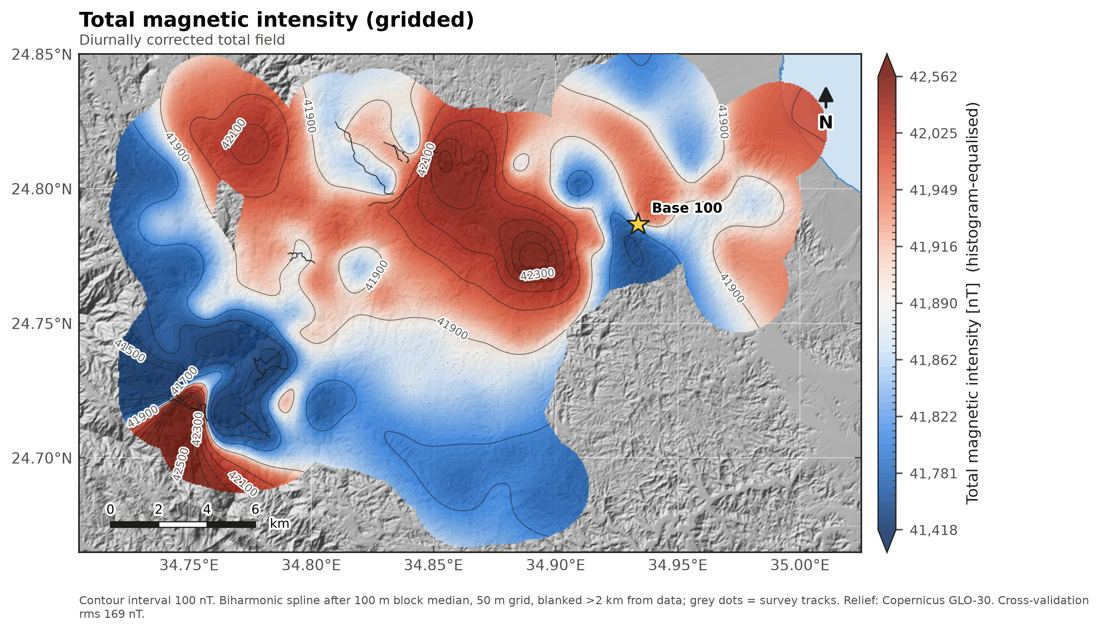

`mag04_TMA_grid.png`

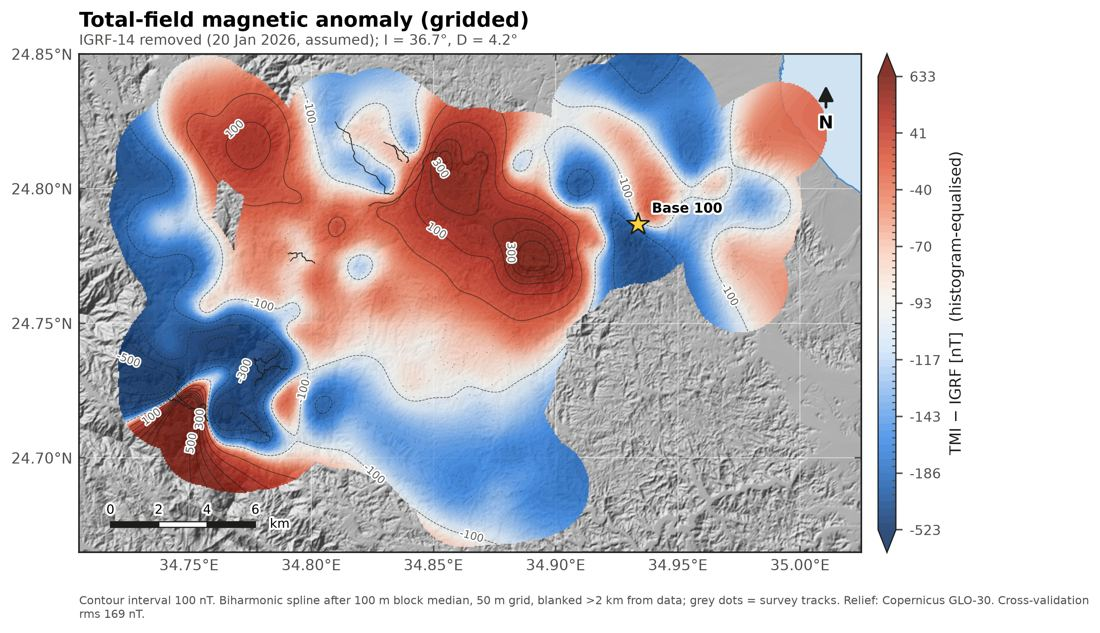

`mag05_RTP_grid.png`

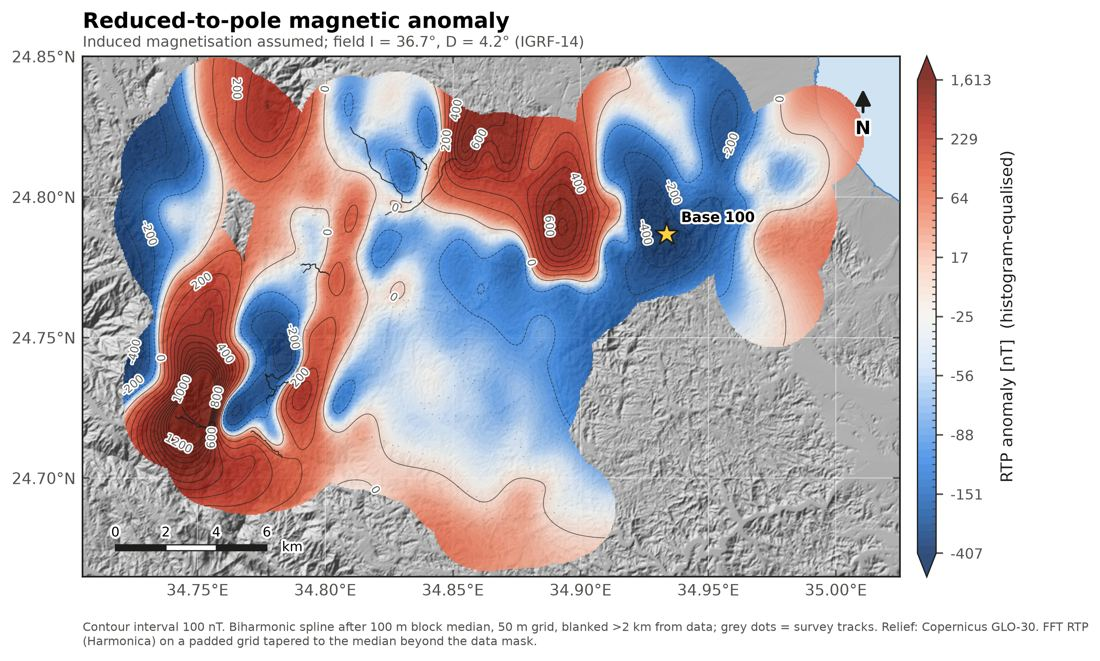

In [8]:
chain.step07_maps()
show_figures(chain.map_dir)

## 8  Export

In [9]:
summary = chain.step08_export()
pd.Series({k: v for k, v in summary.items()}, dtype=object).to_frame("value")

[8] tables, grids and Wadi_Ghadir_Magnetic_Results.xlsx written to ../outputs


,value
Source file,All_Data_Corrected_Total_Intensity.xlsx
Rows,12163
Survey readings,12161
Accepted,12006
Rejected spikes,155
Non-data rows,2
Survey days (from time stamps),10
IGRF model / date,"IGRF-14, 2026-01-20 (assumed: no dates in the ..."
Field inclination / declination (median),36.74° / 4.22°
Despike,"Hampel, window 11, k = 6.0, floor 30.0 nT"


## Results

| Location in `outputs/` | Content |
|---|---|
| `deliverables/Wadi_Ghadir_Magnetic_Results.xlsx` | README, all readings with QC flags, IGRF and TMA, day summary, crossovers, IGRF date sensitivity |
| `magnetics/` | maps mag01–mag05 (TMI points, TMA points, TMI grid, TMA grid, RTP grid) |
| `grids/mag_tmi`, `mag_tma`, `mag_rtp` | grids as NetCDF and XYZ CSV (lon, lat, UTM 36N, value) |
| `tables/30–33` | readings with QC, day summary, crossovers, IGRF date sensitivity |
| `magnetics_summary.json` | key numbers of the run |

*Prepared by Dr. Mohamed Sobh, LIAG.*